In [1]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import numpy as np
dataset_path = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"
classes = sorted(os.listdir(dataset_path))
for classe in classes:
    print (classe)
print(f"Nombre de classes : {len(classes)}")
print("\nToutes les classes :")
for i, c in enumerate(classes):
    count = len(os.listdir(os.path.join(dataset_path, c)))
    print(f"  {i:02d}. {c} — {count} images")

Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy
Nombre de classe

In [2]:
soybean_classes = [c for c in classes if 'Soybean' in c]

In [3]:
classes_maroc=[c for c in classes if c not in soybean_classes]
print(classes_maroc)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato

In [4]:
# ── 1. Transformations ──────────────────────────────────────────────────────
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ── 2. Chargement ────────────────────────────────────────────────────────────
dataset_complet = datasets.ImageFolder(root=dataset_path)

# ── 3. Remapping des labels 0 → 36 ──────────────────────────────────────────
# PROBLÈME PRÉCÉDENT : on filtrait les images mais les labels
# gardaient leurs anciens indices (ex: label 37 existait encore)
# SOLUTION : créer un nouveau mapping propre de 0 à 36

ancien_vers_nouveau = {
    dataset_complet.class_to_idx[c]: i
    for i, c in enumerate(classes_maroc)
}
# Exemple : {0:0, 1:1, ..., 23:23, 25:24, ..., 37:36}
# (le 24 = Soybean est ignoré, tout ce qui suit est décalé)

NUM_CLASSES = len(classes_maroc)  # 37
print(f"NUM_CLASSES : {NUM_CLASSES}")

# ── 4. Filtrage + collecte des nouveaux labels ───────────────────────────────
indices_maroc  = []
labels_remappes = []

for i, (path, label) in enumerate(dataset_complet.samples):
    if label in ancien_vers_nouveau:
        indices_maroc.append(i)
        labels_remappes.append(ancien_vers_nouveau[label])

print(f"Images totales  : {len(dataset_complet)}")
print(f"Images gardées  : {len(indices_maroc)}")

# Vérification — le label max doit être 36
print(f"Label max       : {max(labels_remappes)}")  # doit être 36
print(f"Label min       : {min(labels_remappes)}")  # doit être 0

# ── 5. Split 80/20 ───────────────────────────────────────────────────────────
np.random.seed(42)
ordre  = np.random.permutation(len(indices_maroc))
split  = int(0.8 * len(ordre))

idx_train = ordre[:split]
idx_val   = ordre[split:]

# ── 6. Dataset avec labels remappés ─────────────────────────────────────────
class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, dataset, indices, labels, transform):
        self.dataset   = dataset
        self.indices   = indices
        self.labels    = labels
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image, _ = self.dataset[self.indices[idx]]  # ignore ancien label
        label    = self.labels[idx]                 # utilise nouveau label
        if self.transform:
            image = self.transform(image)
        return image, label

train_dataset = TransformSubset(
    dataset_complet,
    [indices_maroc[i]   for i in idx_train],
    [labels_remappes[i] for i in idx_train],
    transform_train
)
val_dataset = TransformSubset(
    dataset_complet,
    [indices_maroc[i]   for i in idx_val],
    [labels_remappes[i] for i in idx_val],
    transform_val
)

# ── 7. DataLoaders ───────────────────────────────────────────────────────────
train_loader = DataLoader(train_dataset, batch_size=32,
                          shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=32,
                          shuffle=False, num_workers=2)

print(f"\nTrain : {len(train_dataset)} images")
print(f"Val   : {len(val_dataset)} images")
print(f"Batches train : {len(train_loader)}")
print(f"Batches val   : {len(val_loader)}")
print("\nDataset prêt ✓")

NUM_CLASSES : 37
Images totales  : 54305
Images gardées  : 49215
Label max       : 36
Label min       : 0

Train : 39372 images
Val   : 9843 images
Batches train : 1231
Batches val   : 308

Dataset prêt ✓


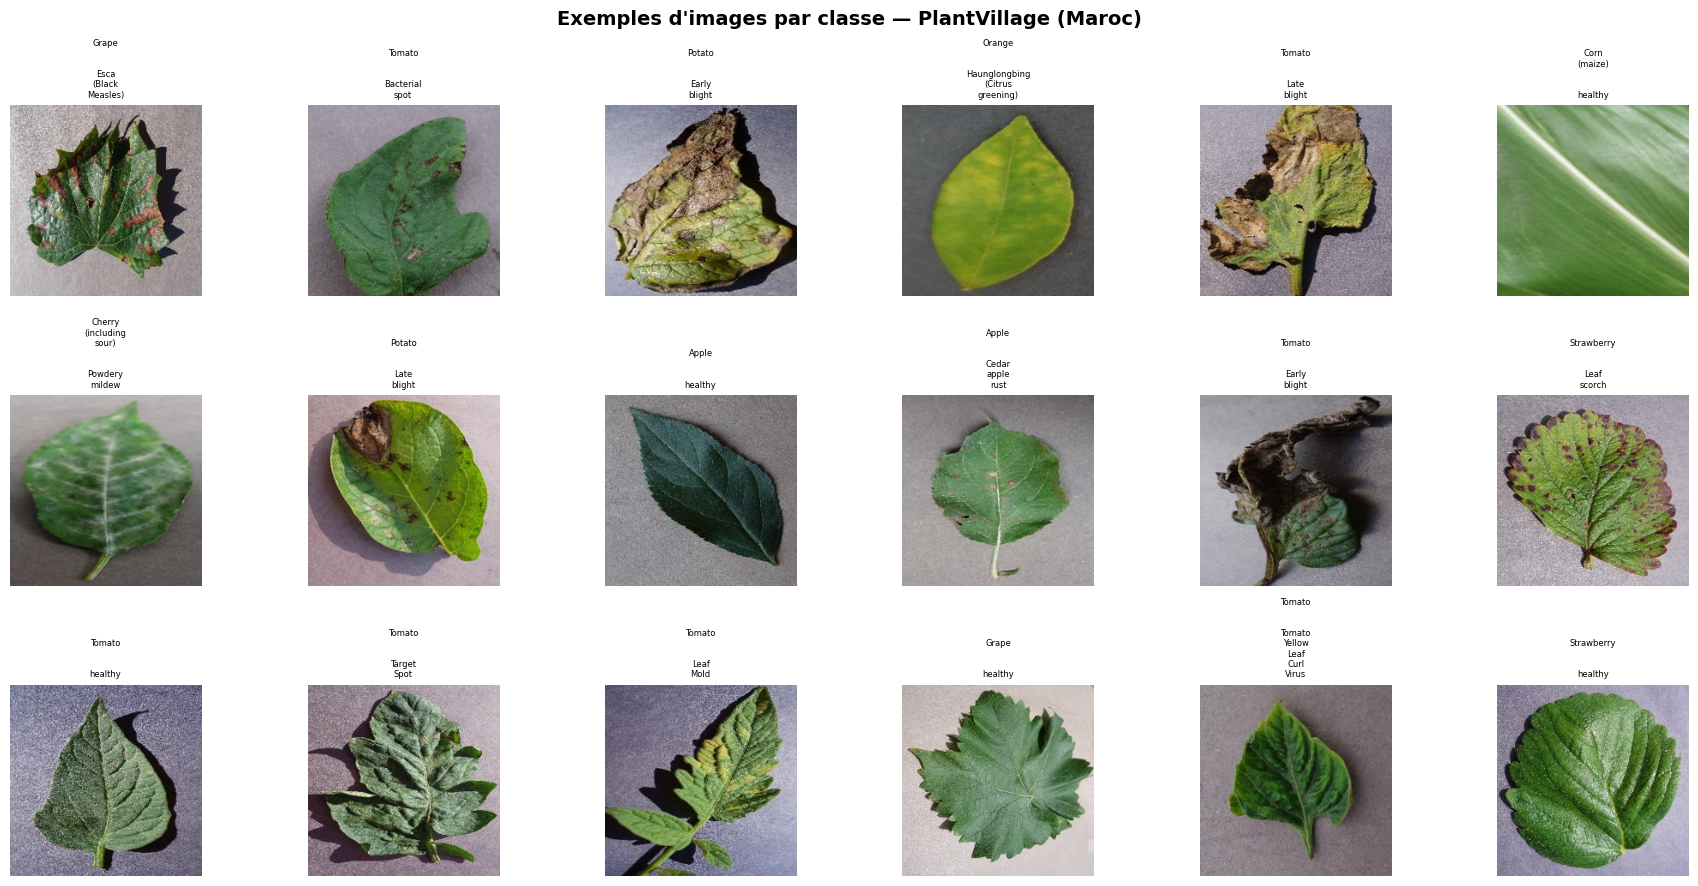

In [5]:
import matplotlib.pyplot as plt
import random
from PIL import Image
import os

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
fig.suptitle('Exemples d\'images par classe — PlantVillage (Maroc)', 
             fontsize=14, fontweight='bold')

selected = random.sample(classes_maroc, 18)
for ax, cls in zip(axes.flatten(), selected):
    cls_path = os.path.join(dataset_path, cls)
    img_file = random.choice(os.listdir(cls_path))
    img = Image.open(os.path.join(cls_path, img_file)).resize((224, 224))
    ax.imshow(img)
    ax.set_title(cls.replace('_', '\n'), fontsize=6)
    ax.axis('off')

plt.tight_layout()
plt.savefig('dataset_samples.png', dpi=150)
plt.show()

In [6]:
import torch
import torch.nn as nn
import timm
from tqdm import tqdm

# ── 1. Charger ResNet50 pré-entraîné ────────────────────────────────────────

model_resnet = timm.create_model('resnet50', pretrained=True)

# Explication : ResNet50 a été entraîné sur ImageNet (1000 classes)
# Sa dernière couche FC prédit 1000 classes → on la remplace par 37
print(f"Couche finale originale : {model_resnet.fc}")
# Linear(in_features=2048, out_features=1000)

model_resnet.fc = nn.Linear(model_resnet.fc.in_features, NUM_CLASSES)
print(f"Couche finale modifiée  : {model_resnet.fc}")
# Linear(in_features=2048, out_features=37)

# ── 2. GPU ou CPU ────────────────────────────────────────────────────────────

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nDevice : {device}")  # Sur Kaggle → cuda
model_resnet = model_resnet.to(device)

# ── 3. Loss + Optimiseur + Scheduler ────────────────────────────────────────

criterion = nn.CrossEntropyLoss()
# CrossEntropyLoss = fonction de perte standard pour classification multi-classe

optimizer = torch.optim.AdamW(model_resnet.parameters(), lr=1e-4)
# AdamW = Adam amélioré, plus stable, lr=0.0001

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=2, factor=0.5
)
# Si val_loss ne s'améliore pas pendant 2 epochs → divise lr par 2

# ── 4. Boucle d'entraînement ─────────────────────────────────────────────────

def train_model(model, train_loader, val_loader, epochs=5):
    
    best_val_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 
               'train_acc': [], 'val_acc': []}
    
    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")
        print("-" * 50)
        
        # ── Phase TRAIN ──
        model.train()  # active dropout, batch norm en mode train
        train_loss, train_correct, train_total = 0, 0, 0
        
        for images, labels in tqdm(train_loader, desc="Train"):
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()        # reset les gradients
            outputs = model(images)      # forward pass
            loss = criterion(outputs, labels)  # calcul de la loss
            loss.backward()              # backpropagation
            optimizer.step()             # mise à jour des poids
            
            train_loss    += loss.item()
            preds          = outputs.argmax(dim=1)
            train_correct += (preds == labels).sum().item()
            train_total   += labels.size(0)
        
        train_acc  = train_correct / train_total
        train_loss = train_loss / len(train_loader)
        
        # ── Phase VALIDATION ──
        model.eval()  # désactive dropout, batch norm en mode eval
        val_loss, val_correct, val_total = 0, 0, 0
        
        with torch.no_grad():  # pas de gradient en validation
            for images, labels in tqdm(val_loader, desc="Val"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss    = criterion(outputs, labels)
                
                val_loss    += loss.item()
                preds        = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()
                val_total   += labels.size(0)
        
        val_acc  = val_correct / val_total
        val_loss = val_loss / len(val_loader)
        
        # Scheduler — réduit lr si val_loss stagne
        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]['lr']
        
        # Sauvegarder le meilleur modèle
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'resnet50_maroc_best.pth')
            print(f"  ✓ Meilleur modèle sauvegardé")
        
        # Afficher les résultats
        print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")
        print(f"  LR actuel:  {current_lr:.6f}")
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
    
    print(f"\nMeilleure Val Accuracy : {best_val_acc:.4f}")
    return history

# ── 5. Lancer l'entraînement ─────────────────────────────────────────────────

history_resnet = train_model(model_resnet, train_loader, val_loader, epochs=5)

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Couche finale originale : Linear(in_features=2048, out_features=1000, bias=True)
Couche finale modifiée  : Linear(in_features=2048, out_features=37, bias=True)

Device : cuda

Epoch 1/5
--------------------------------------------------


Val: 100%|██████████| 308/308 [00:40<00:00,  7.52it/s]


  ✓ Meilleur modèle sauvegardé
  Train Loss: 0.9793 | Train Acc: 0.7526
  Val Loss:   0.0814 | Val Acc:   0.9785
  LR actuel:  0.000100

Epoch 2/5
--------------------------------------------------


Val: 100%|██████████| 308/308 [00:32<00:00,  9.44it/s]


  ✓ Meilleur modèle sauvegardé
  Train Loss: 0.0978 | Train Acc: 0.9718
  Val Loss:   0.0333 | Val Acc:   0.9899
  LR actuel:  0.000100

Epoch 3/5
--------------------------------------------------


... (2 outputs left out)

Val: 100%|██████████| 308/308 [00:32<00:00,  9.46it/s]


  ✓ Meilleur modèle sauvegardé
  Train Loss: 0.0356 | Train Acc: 0.9892
  Val Loss:   0.0174 | Val Acc:   0.9946
  LR actuel:  0.000100

Epoch 5/5
--------------------------------------------------


Val: 100%|██████████| 308/308 [00:32<00:00,  9.48it/s]

  Train Loss: 0.0276 | Train Acc: 0.9919
  Val Loss:   0.0190 | Val Acc:   0.9943
  LR actuel:  0.000100

Meilleure Val Accuracy : 0.9946


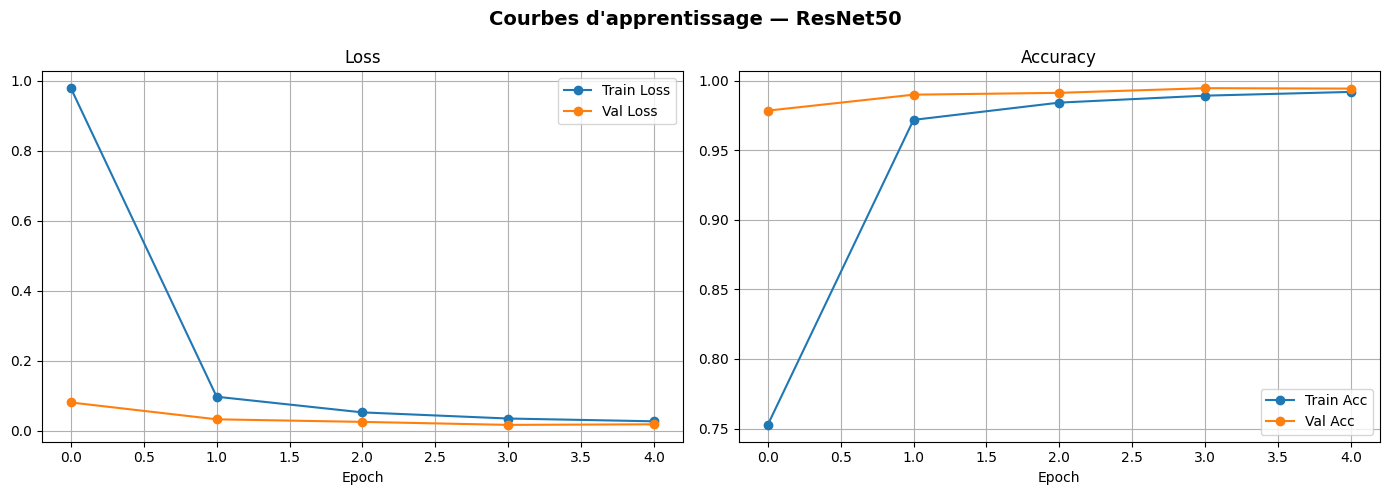

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Courbes d\'apprentissage — ResNet50', fontsize=14, fontweight='bold')

axes[0].plot(history_resnet['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history_resnet['val_loss'], label='Val Loss', marker='o')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_resnet['train_acc'], label='Train Acc', marker='o')
axes[1].plot(history_resnet['val_acc'], label='Val Acc', marker='o')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('training_curves_resnet.png', dpi=150)
plt.show()

In [9]:
import timm
import torch
import torch.nn as nn

# ── 1. Charger ViT pré-entraîné ─────────────────────────────────────────────

model_vit = timm.create_model('vit_base_patch16_224', pretrained=True)

# ViT original a 1000 classes (ImageNet)
# On remplace la tête de classification
print(f"Tête originale : {model_vit.head}")
# Linear(in_features=768, out_features=1000)

model_vit.head = nn.Linear(model_vit.head.in_features, NUM_CLASSES)
print(f"Tête modifiée  : {model_vit.head}")
# Linear(in_features=768, out_features=37)

# ── 2. Différence avec ResNet ────────────────────────────────────────────────
# ResNet  → model_resnet.fc    (2048 features)
# ViT     → model_vit.head     (768 features)
# Pourquoi 768 ? C'est la dimension des embeddings du Transformer

model_vit = model_vit.to(device)

# ── 3. Entraînement — exactement le même que ResNet ─────────────────────────

optimizer_vit = torch.optim.AdamW(model_vit.parameters(), lr=1e-4)
scheduler_vit = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_vit, mode='min', patience=2, factor=0.5
)

def train_model_vit(model, train_loader, val_loader, epochs=5):
    
    best_val_acc = 0.0
    history = {'train_loss': [], 'val_loss': [],
               'train_acc': [], 'val_acc': []}
    
    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")
        print("-" * 50)
        
        # Phase TRAIN
        model.train()
        train_loss, train_correct, train_total = 0, 0, 0
        
        for images, labels in tqdm(train_loader, desc="Train"):
            images, labels = images.to(device), labels.to(device)
            
            optimizer_vit.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer_vit.step()
            
            train_loss    += loss.item()
            preds          = outputs.argmax(dim=1)
            train_correct += (preds == labels).sum().item()
            train_total   += labels.size(0)
        
        train_acc  = train_correct / train_total
        train_loss = train_loss / len(train_loader)
        
        # Phase VALIDATION
        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        
        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Val"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss    = criterion(outputs, labels)
                
                val_loss    += loss.item()
                preds        = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()
                val_total   += labels.size(0)
        
        val_acc  = val_correct / val_total
        val_loss = val_loss / len(val_loader)
        
        scheduler_vit.step(val_loss)
        current_lr = optimizer_vit.param_groups[0]['lr']
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'vit_maroc_best.pth')
            print(f"  ✓ Meilleur modèle sauvegardé")
        
        print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")
        print(f"  LR actuel:  {current_lr:.6f}")
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
    
    print(f"\nMeilleure Val Accuracy : {best_val_acc:.4f}")
    return history

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Tête originale : Linear(in_features=768, out_features=1000, bias=True)
Tête modifiée  : Linear(in_features=768, out_features=37, bias=True)


In [11]:
history_vit = train_model_vit(model_vit, train_loader, val_loader, epochs=5)


Epoch 1/5
--------------------------------------------------


Val: 100%|██████████| 308/308 [01:55<00:00,  2.67it/s]


  ✓ Meilleur modèle sauvegardé
  Train Loss: 0.1124 | Train Acc: 0.9637
  Val Loss:   0.0507 | Val Acc:   0.9839
  LR actuel:  0.000100

Epoch 2/5
--------------------------------------------------


Val: 100%|██████████| 308/308 [01:55<00:00,  2.67it/s]


  Train Loss: 0.0714 | Train Acc: 0.9779
  Val Loss:   0.0758 | Val Acc:   0.9744
  LR actuel:  0.000100

Epoch 3/5
--------------------------------------------------


Val: 100%|██████████| 308/308 [01:55<00:00,  2.67it/s]


  ✓ Meilleur modèle sauvegardé
  Train Loss: 0.0594 | Train Acc: 0.9810
  Val Loss:   0.0327 | Val Acc:   0.9903
  LR actuel:  0.000100

Epoch 4/5
--------------------------------------------------


Val: 100%|██████████| 308/308 [01:55<00:00,  2.67it/s]


  Train Loss: 0.0564 | Train Acc: 0.9821
  Val Loss:   0.0640 | Val Acc:   0.9798
  LR actuel:  0.000100

Epoch 5/5
--------------------------------------------------


Val: 100%|██████████| 308/308 [01:55<00:00,  2.67it/s]

  Train Loss: 0.0504 | Train Acc: 0.9834
  Val Loss:   0.0335 | Val Acc:   0.9897
  LR actuel:  0.000100

Meilleure Val Accuracy : 0.9903


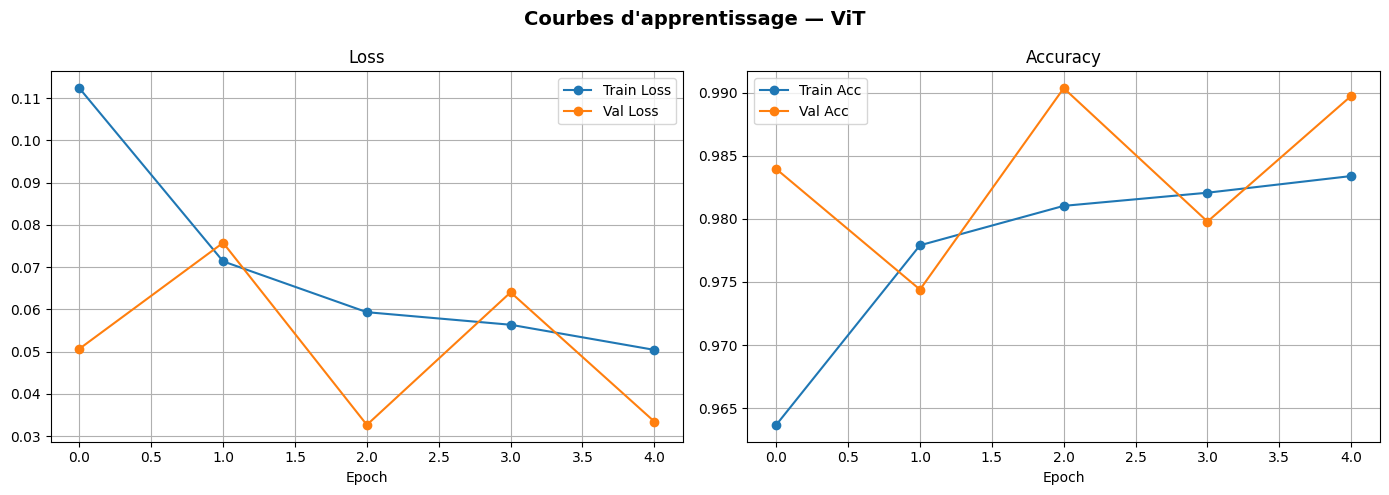

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Courbes d\'apprentissage — ViT', fontsize=14, fontweight='bold')

axes[0].plot(history_vit['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history_vit['val_loss'], label='Val Loss', marker='o')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_vit['train_acc'], label='Train Acc', marker='o')
axes[1].plot(history_vit['val_acc'], label='Val Acc', marker='o')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('training_curves_vit.png', dpi=150)
plt.show()

Classe : Tomato___Late_blight
Shape : torch.Size([12, 197, 197])


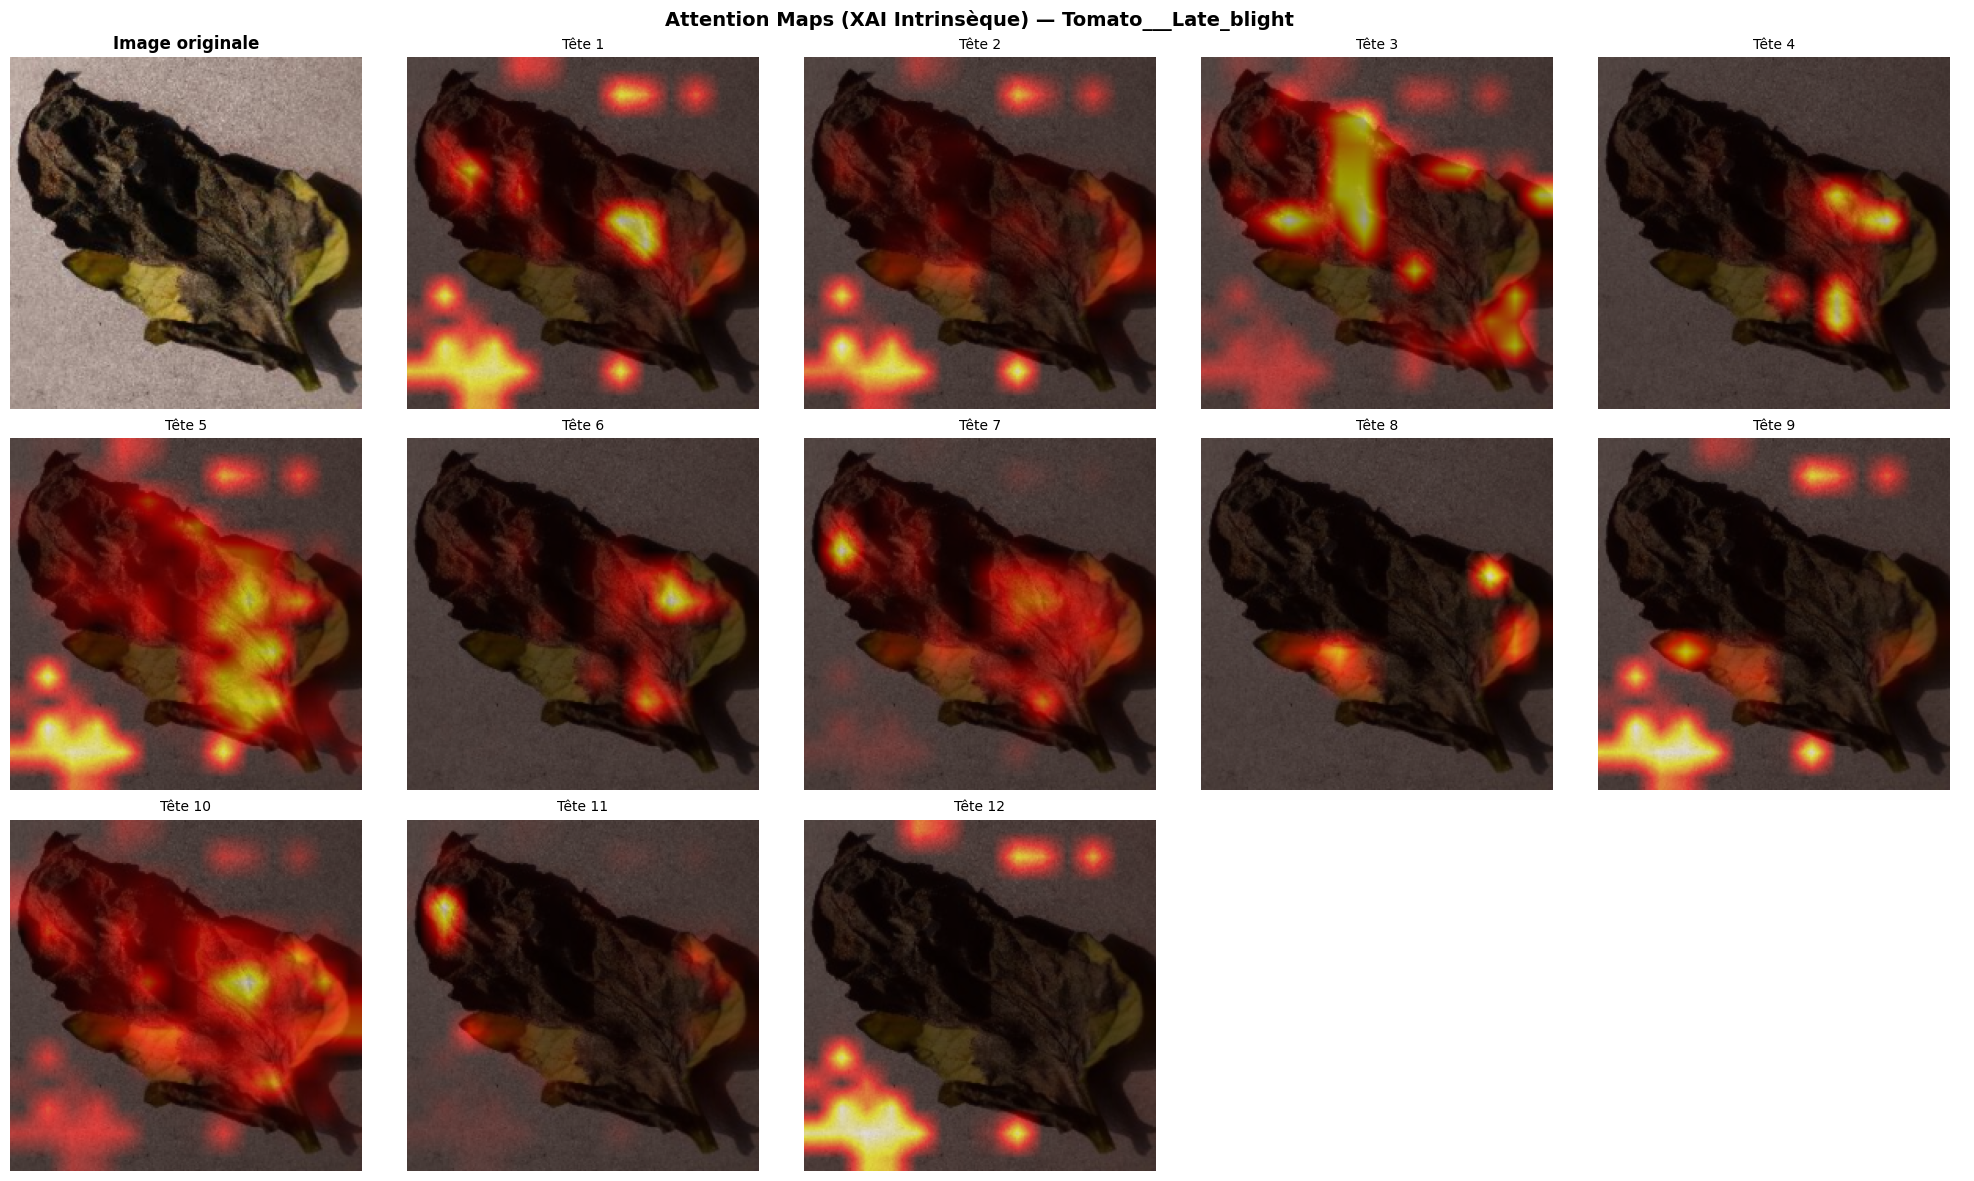

Sauvegardé : attention_maps.png ✓


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

def get_attention_maps(model, image_tensor):
    """
    Extrait les attention maps en hookant le module qkv
    de la dernière couche du ViT.
    """
    model.eval()
    attention_maps = []

    def hook_fn(module, input, output):
        # output de qkv : [1, 197, 3 * 768]
        # On reconstruit Q et K pour calculer l'attention
        B, N, _ = output.shape
        num_heads = 12
        head_dim  = 768 // num_heads  # 64

        # Séparer Q, K, V
        qkv = output.reshape(B, N, 3, num_heads, head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # [3, B, heads, N, head_dim]
        q, k, v = qkv[0], qkv[1], qkv[2]  # chacun : [B, heads, N, head_dim]

        # Calculer les scores d'attention
        scale = head_dim ** -0.5
        attn  = (q @ k.transpose(-2, -1)) * scale  # [B, heads, N, N]
        attn  = attn.softmax(dim=-1)                # normaliser

        attention_maps.append(attn.detach().cpu())

    # Hook sur qkv de la dernière couche (blocks.11)
    hook = model.blocks[-1].attn.qkv.register_forward_hook(hook_fn)

    with torch.no_grad():
        _ = model(image_tensor.unsqueeze(0).to(device))

    hook.remove()

    # Shape : [1, 12, 197, 197]
    attn = attention_maps[0].squeeze(0)  # [12, 197, 197]
    return attn


def visualiser_attention_maps(image_tensor, attn_maps, classes_maroc, label):
    """
    Affiche l'image originale + les 12 têtes d'attention.
    Rouge/jaune = zones que le modèle regarde le plus.
    """
    # Dénormaliser l'image
    mean = torch.tensor([0.485, 0.456, 0.406])
    std  = torch.tensor([0.229, 0.224, 0.225])
    img  = image_tensor.cpu() * std[:, None, None] + mean[:, None, None]
    img  = img.permute(1, 2, 0).numpy()
    img  = np.clip(img, 0, 1)

    fig, axes = plt.subplots(3, 5, figsize=(20, 12))
    fig.suptitle(f'Attention Maps (XAI Intrinsèque) — {classes_maroc[label]}',
                 fontsize=14, fontweight='bold')

    # Image originale
    axes[0, 0].imshow(img)
    axes[0, 0].set_title('Image originale', fontweight='bold')
    axes[0, 0].axis('off')

    # 12 têtes
    for head_idx in range(12):
        row = (head_idx + 1) // 5
        col = (head_idx + 1) % 5

        # Attention du token CLS vers les 196 patches
        attn_head = attn_maps[head_idx, 0, 1:]       # [196]
        attn_grid = attn_head.reshape(14, 14).numpy() # 14×14

        # Upscale 14×14 → 224×224
        attn_resized = F.interpolate(
            torch.tensor(attn_grid).unsqueeze(0).unsqueeze(0).float(),
            size=(224, 224),
            mode='bilinear',
            align_corners=False
        ).squeeze().numpy()

        # Superposer sur l'image
        axes[row, col].imshow(img)
        axes[row, col].imshow(attn_resized, alpha=0.6, cmap='hot')
        axes[row, col].set_title(f'Tête {head_idx + 1}', fontsize=10)
        axes[row, col].axis('off')

    # Cacher case vide
    for ax in [axes[2, 3], axes[2, 4]]:
        ax.axis('off')

    plt.tight_layout()
    plt.savefig('attention_maps.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Sauvegardé : attention_maps.png ✓")


# ── Lancer ───────────────────────────────────────────────────────────────────

# Prendre une image de la validation
image_tensor, label = val_dataset[42]
print(f"Classe : {classes_maroc[label]}")

# Extraire
attn_maps = get_attention_maps(model_vit, image_tensor)
print(f"Shape : {attn_maps.shape}")  # [12, 197, 197]

# Visualiser
visualiser_attention_maps(image_tensor, attn_maps, classes_maroc, label)

In [14]:
!pip install grad-cam --quiet
import importlib
import pytorch_grad_cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 94.2 MB/s eta 0:00:00:00:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 89.6 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda

Classe : Tomato___Late_blight


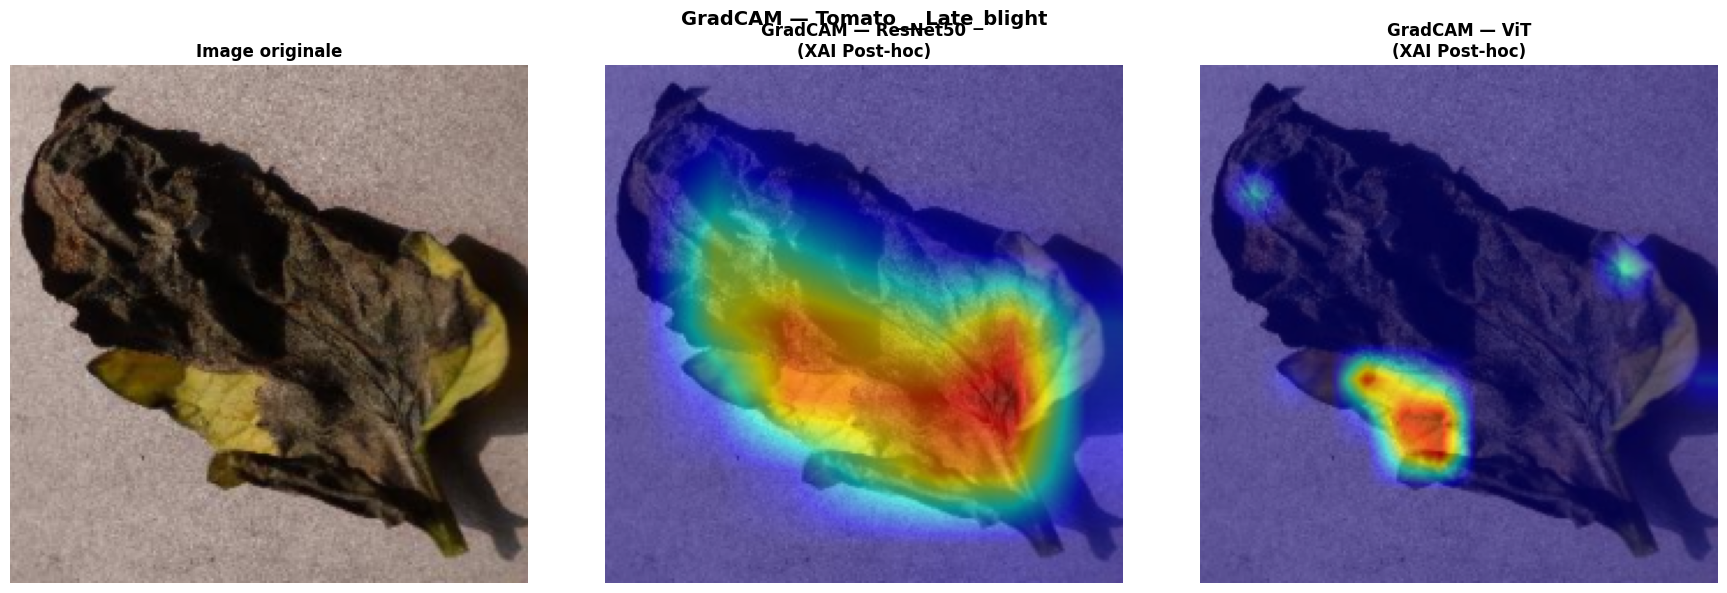

Sauvegardé : gradcam_comparison.png ✓


In [15]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ── 1. Préparer l'image ──────────────────────────────────────────────────────

def preparer_image(dataset, idx=42):
    """Retourne image tensor + image RGB dénormalisée pour affichage."""
    image_tensor, label = dataset[idx]
    
    # Dénormaliser pour affichage
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = image_tensor.permute(1, 2, 0).numpy()
    img  = (img * std + mean)
    img  = np.clip(img, 0, 1).astype(np.float32)
    
    return image_tensor, img, label

image_tensor, img_rgb, label = preparer_image(val_dataset, idx=42)
print(f"Classe : {classes_maroc[label]}")

# ── 2. GradCAM sur ResNet50 ──────────────────────────────────────────────────

# La dernière couche conv de ResNet50 = layer4
target_layers_resnet = [model_resnet.layer4[-1]]

cam_resnet = GradCAM(
    model=model_resnet,
    target_layers=target_layers_resnet
)

targets = [ClassifierOutputTarget(label)]

# Générer la carte GradCAM
grayscale_cam_resnet = cam_resnet(
    input_tensor=image_tensor.unsqueeze(0).to(device),
    targets=targets
)[0]  # [224, 224]

# Superposer sur l'image
visualization_resnet = show_cam_on_image(img_rgb, grayscale_cam_resnet, use_rgb=True)

# ── 3. GradCAM sur ViT ───────────────────────────────────────────────────────

# Pour ViT, on utilise la dernière couche de normalisation
# pytorch_grad_cam a un wrapper spécial pour ViT

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Reshape transform nécessaire pour ViT
def reshape_transform_vit(tensor, height=14, width=14):
    """
    Le ViT retourne [batch, 197, 768]
    On enlève le token CLS et on reshape en grille 14×14
    """
    result = tensor[:, 1:, :]          # enlever CLS token → [B, 196, 768]
    result = result.reshape(
        result.size(0), height, width, result.size(2)
    )                                   # [B, 14, 14, 768]
    result = result.transpose(2, 3).transpose(1, 2)  # [B, 768, 14, 14]
    return result

# Dernière couche du ViT
target_layers_vit = [model_vit.blocks[-1].norm1]

cam_vit = GradCAM(
    model=model_vit,
    target_layers=target_layers_vit,
    reshape_transform=reshape_transform_vit
)

grayscale_cam_vit = cam_vit(
    input_tensor=image_tensor.unsqueeze(0).to(device),
    targets=targets
)[0]  # [224, 224]

visualization_vit = show_cam_on_image(img_rgb, grayscale_cam_vit, use_rgb=True)

# ── 4. Affichage comparatif ──────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(f'GradCAM — {classes_maroc[label]}', 
             fontsize=14, fontweight='bold')

axes[0].imshow(img_rgb)
axes[0].set_title('Image originale', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(visualization_resnet)
axes[1].set_title('GradCAM — ResNet50\n(XAI Post-hoc)', fontweight='bold')
axes[1].axis('off')

axes[2].imshow(visualization_vit)
axes[2].set_title('GradCAM — ViT\n(XAI Post-hoc)', fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.savefig('gradcam_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sauvegardé : gradcam_comparison.png ✓")

LIME en cours... (30-60 secondes)


  0%|          | 0/1000 [00:00<?, ?it/s]

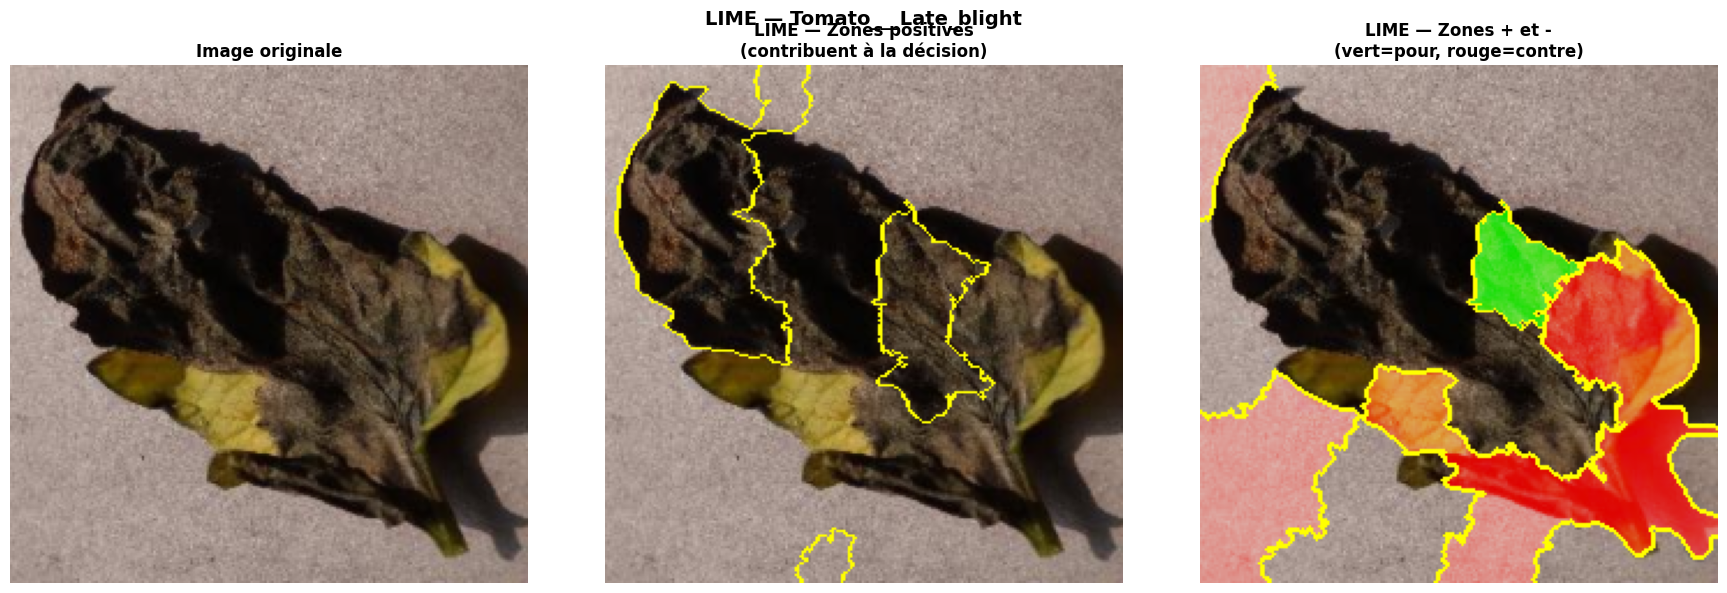

Sauvegardé : lime_explanation.png ✓


In [16]:
from lime import lime_image
from skimage.segmentation import mark_boundaries
import numpy as np
import matplotlib.pyplot as plt
import torch

# ── 1. Fonction de prédiction pour LIME ─────────────────────────────────────
# LIME travaille avec des images numpy [0,255]
# Il faut une fonction qui prend un batch numpy et retourne des probabilités

def predict_fn_resnet(images):
    """
    LIME donne des images numpy float [0,1] shape [N, H, W, C]
    On doit retourner des probabilités shape [N, NUM_CLASSES]
    """
    model_resnet.eval()
    
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    
    batch = []
    for img in images:
        img_norm = (img - mean) / std           # normaliser
        img_t    = torch.tensor(img_norm).permute(2, 0, 1).float()
        batch.append(img_t)
    
    batch_tensor = torch.stack(batch).to(device)
    
    with torch.no_grad():
        outputs = model_resnet(batch_tensor)
        probs   = torch.softmax(outputs, dim=1)
    
    return probs.cpu().numpy()

# ── 2. Préparer l'image pour LIME ────────────────────────────────────────────

# LIME veut une image numpy float32 [H, W, C] entre 0 et 1
mean = np.array([0.485, 0.456, 0.406])
std  = np.array([0.229, 0.224, 0.225])

img_numpy = image_tensor.permute(1, 2, 0).numpy()
img_numpy = (img_numpy * std + mean)           # dénormaliser
img_numpy = np.clip(img_numpy, 0, 1).astype(np.float32)

# ── 3. Lancer LIME ───────────────────────────────────────────────────────────

explainer = lime_image.LimeImageExplainer()

print("LIME en cours... (30-60 secondes)")
explanation = explainer.explain_instance(
    img_numpy,
    predict_fn_resnet,
    top_labels=1,          # expliquer seulement la classe prédite
    hide_color=0,          # remplacer superpixels par du noir
    num_samples=1000       # nombre de perturbations
)

# ── 4. Visualiser ────────────────────────────────────────────────────────────

# Superpixels positifs = contribuent À la prédiction
# Superpixels négatifs = vont CONTRE la prédiction
temp, mask = explanation.get_image_and_mask(
    explanation.top_labels[0],
    positive_only=True,    # montrer seulement ce qui aide
    num_features=10,       # top 10 superpixels
    hide_rest=False
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(f'LIME — {classes_maroc[label]}', fontsize=14, fontweight='bold')

# Image originale
axes[0].imshow(img_numpy)
axes[0].set_title('Image originale', fontweight='bold')
axes[0].axis('off')

# Zones positives seulement
axes[1].imshow(mark_boundaries(temp, mask))
axes[1].set_title('LIME — Zones positives\n(contribuent à la décision)', fontweight='bold')
axes[1].axis('off')

# Zones positives ET négatives
temp2, mask2 = explanation.get_image_and_mask(
    explanation.top_labels[0],
    positive_only=False,
    num_features=10,
    hide_rest=False
)
axes[2].imshow(mark_boundaries(temp2, mask2))
axes[2].set_title('LIME — Zones + et -\n(vert=pour, rouge=contre)', fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.savefig('lime_explanation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sauvegardé : lime_explanation.png ✓")

In [17]:
!pip install shap -q

In [18]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import numpy as np

# ── Paramètres ────────────────────────────────────────────────────────────────
dataset_path = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"
device       = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── Classes ───────────────────────────────────────────────────────────────────
classes        = sorted(os.listdir(dataset_path))
soybean_classes = [c for c in classes if 'Soybean' in c]
classes_maroc  = [c for c in classes if c not in soybean_classes]
NUM_CLASSES    = len(classes_maroc)  # 37

# ── Transform val ─────────────────────────────────────────────────────────────
transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ── Dataset filtré (sans Soybean) ─────────────────────────────────────────────
dataset_complet   = datasets.ImageFolder(root=dataset_path)
ancien_vers_nouveau = {
    dataset_complet.class_to_idx[c]: i
    for i, c in enumerate(classes_maroc)
}

indices_maroc, new_labels = [], []
for idx, (path, old_label) in enumerate(dataset_complet.samples):
    if old_label in ancien_vers_nouveau:
        indices_maroc.append(idx)
        new_labels.append(ancien_vers_nouveau[old_label])

# ── Split train / val ─────────────────────────────────────────────────────────
from torch.utils.data import random_split

subset = Subset(dataset_complet, indices_maroc)

# Appliquer les nouveaux labels
class CustomSubset(torch.utils.data.Dataset):
    def __init__(self, subset, new_labels, transform):
        self.subset     = subset
        self.new_labels = new_labels
        self.transform  = transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, i):
        img, _ = self.subset[i]
        img    = self.transform(img) if not torch.is_tensor(img) else img
        return img, self.new_labels[i]

dataset_val_full = CustomSubset(subset, new_labels, transform_val)

val_size  = int(0.2 * len(dataset_val_full))
train_size = len(dataset_val_full) - val_size
_, val_dataset = random_split(
    dataset_val_full, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
print(f"val_loader prêt — {len(val_dataset)} images ✓")

val_loader prêt — 9843 images ✓


Classe : Orange___Haunglongbing_(Citrus_greening)


  0%|          | 0/1000 [00:00<?, ?it/s]

SHAP — nb arrays : 1, shape[0] : (3, 224, 224, 37)
shap_map shape : (224, 37)


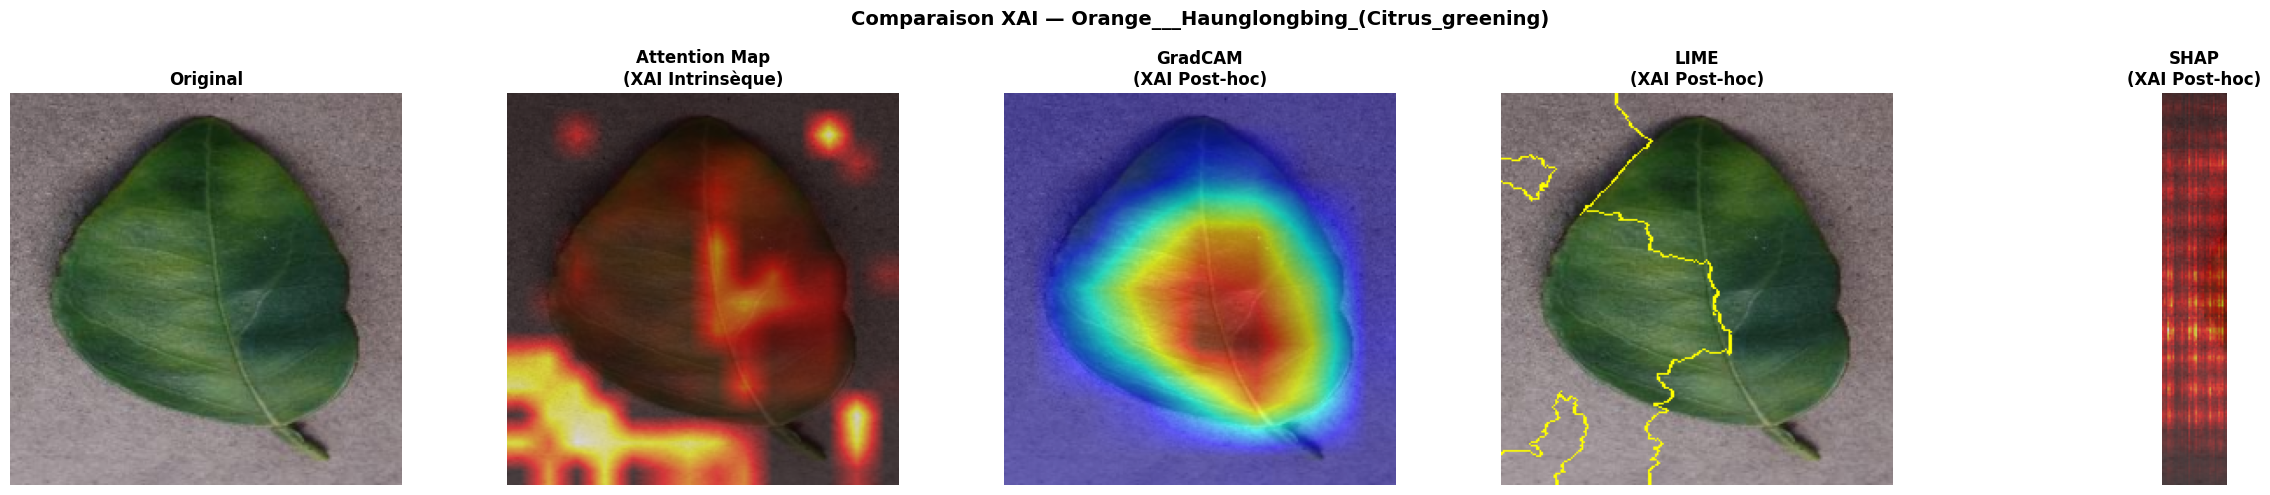

Sauvegardé : xai_comparison.png ✓


In [19]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries
from lime import lime_image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import shap

# ─── 1. Image de référence (idx=42) ──────────────────────────────────────────
image_tensor, label = val_dataset[42]
print(f"Classe : {classes_maroc[label]}")

# ─── 2. img_np : image dénormalisée ──────────────────────────────────────────
mean         = np.array([0.485, 0.456, 0.406])
std          = np.array([0.229, 0.224, 0.225])
img_np       = image_tensor.permute(1, 2, 0).numpy()
img_np       = np.clip(img_np * std + mean, 0, 1)
img_np_uint8 = (img_np * 255).astype(np.uint8)
img_np_float = img_np.astype(np.float32)

# ─── 3. Attention Map (ViT — tête 10) ────────────────────────────────────────
attn_maps = get_attention_maps(model_vit, image_tensor)

attn_head = attn_maps[9, 0, 1:].reshape(14, 14)
attn_up   = F.interpolate(
    attn_head.unsqueeze(0).unsqueeze(0).float(),
    size=(224, 224), mode='bilinear', align_corners=False
).squeeze().numpy()

# ─── 4. GradCAM (ResNet50) ───────────────────────────────────────────────────
cam_resnet = GradCAM(
    model=model_resnet,
    target_layers=[model_resnet.layer4[-1]]
)
grayscale_cam = cam_resnet(
    input_tensor=image_tensor.unsqueeze(0).to(device),
    targets=[ClassifierOutputTarget(label)]
)[0]
visualization_resnet = show_cam_on_image(img_np_float, grayscale_cam, use_rgb=True)

# ─── 5. LIME ─────────────────────────────────────────────────────────────────
lime_explainer = lime_image.LimeImageExplainer()
explanation    = lime_explainer.explain_instance(
    img_np_float,
    predict_fn_resnet,
    top_labels=1,
    hide_color=0,
    num_samples=1000
)
temp_lime, mask_lime = explanation.get_image_and_mask(
    explanation.top_labels[0],
    positive_only=True,
    num_features=10,
    hide_rest=False
)

# ─── 6. SHAP (GradientExplainer — compatible ViT) ────────────────────────────
background_imgs = torch.stack([val_dataset[i][0] for i in range(20)]).to(device)
explainer_s     = shap.GradientExplainer(model_vit, background_imgs)

shap_values = explainer_s.shap_values(
    image_tensor.unsqueeze(0).to(device)
)

# Détection automatique du format retourné
print(f"SHAP — nb arrays : {len(shap_values)}, shape[0] : {np.array(shap_values[0]).shape}")

if len(shap_values) == NUM_CLASSES:
    # Une entrée par classe [37 x (1, 3, 224, 224)] → indexer par label
    shap_arr = np.array(shap_values[label])
elif len(shap_values) == 1:
    # Un seul array agrégé (1, 3, 224, 224)
    shap_arr = np.array(shap_values[0])
else:
    # Fallback : premier array disponible
    shap_arr = np.array(shap_values[0])

shap_map = np.abs(shap_arr[0]).sum(axis=0)   # [224, 224]
shap_map = (shap_map - shap_map.min()) / (shap_map.max() - shap_map.min() + 1e-8)
print(f"shap_map shape : {shap_map.shape}")  # doit être (224, 224)

# ─── 7. Visualisation finale ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
fig.suptitle(f'Comparaison XAI — {classes_maroc[label]}',
             fontsize=14, fontweight='bold')

# 1. Image originale
axes[0].imshow(img_np_uint8)
axes[0].set_title('Original', fontweight='bold')
axes[0].axis('off')

# 2. Attention Map
axes[1].imshow(img_np_uint8)
axes[1].imshow(attn_up, alpha=0.6, cmap='hot')
axes[1].set_title('Attention Map\n(XAI Intrinsèque)', fontweight='bold')
axes[1].axis('off')

# 3. GradCAM
axes[2].imshow(visualization_resnet)
axes[2].set_title('GradCAM\n(XAI Post-hoc)', fontweight='bold')
axes[2].axis('off')

# 4. LIME
axes[3].imshow(mark_boundaries(temp_lime, mask_lime))
axes[3].set_title('LIME\n(XAI Post-hoc)', fontweight='bold')
axes[3].axis('off')

# 5. SHAP
axes[4].imshow(img_np_uint8)
axes[4].imshow(shap_map, alpha=0.6, cmap='hot')
axes[4].set_title('SHAP\n(XAI Post-hoc)', fontweight='bold')
axes[4].axis('off')

plt.tight_layout()
plt.savefig('xai_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Sauvegardé : xai_comparison.png ✓")

In [24]:
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries
from lime import lime_image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import shap

# ─── 1. Image de référence (idx=42) ──────────────────────────────────────────
image_tensor, label = val_dataset[42]
print(f"Classe : {classes_maroc[label]}")

# ─── 2. img_np : image dénormalisée ──────────────────────────────────────────
mean         = np.array([0.485, 0.456, 0.406])
std          = np.array([0.229, 0.224, 0.225])
img_np       = image_tensor.permute(1, 2, 0).numpy()
img_np       = np.clip(img_np * std + mean, 0, 1)
img_np_uint8 = (img_np * 255).astype(np.uint8)
img_np_float = img_np.astype(np.float32)

# ─── 3. Attention Map (ViT — tête 10) ────────────────────────────────────────
attn_maps = get_attention_maps(model_vit, image_tensor)

attn_head = attn_maps[9, 0, 1:].reshape(14, 14)
attn_up   = F.interpolate(
    attn_head.unsqueeze(0).unsqueeze(0).float(),
    size=(224, 224), mode='bilinear', align_corners=False
).squeeze().numpy()

# ─── 4. GradCAM (ResNet50) — modèle frais sans hooks SHAP ───────────────────
# Recharger ResNet50 propre pour éviter le conflit avec les hooks SHAP
model_resnet_cam = timm.create_model('resnet50', pretrained=False, num_classes=NUM_CLASSES)
model_resnet_cam.load_state_dict(model_resnet.state_dict())
model_resnet_cam = model_resnet_cam.to(device)
model_resnet_cam.eval()

cam_resnet = GradCAM(
    model=model_resnet_cam,
    target_layers=[model_resnet_cam.layer4[-1]]
)
grayscale_cam = cam_resnet(
    input_tensor=image_tensor.unsqueeze(0).to(device),
    targets=[ClassifierOutputTarget(label)]
)[0]
visualization_resnet = show_cam_on_image(img_np_float, grayscale_cam, use_rgb=True)

# ─── 5. LIME ─────────────────────────────────────────────────────────────────
lime_explainer = lime_image.LimeImageExplainer()
explanation    = lime_explainer.explain_instance(
    img_np_float,
    predict_fn_resnet,
    top_labels=1,
    hide_color=0,
    num_samples=1000
)
temp_lime, mask_lime = explanation.get_image_and_mask(
    explanation.top_labels[0],
    positive_only=True,
    num_features=10,
    hide_rest=False
)

# ─── 6. SHAP (GradientExplainer — ViT) ───────────────────────────────────────
def disable_inplace(model):
    for module in model.modules():
        if isinstance(module, torch.nn.ReLU):
            module.inplace = False

disable_inplace(model_vit)
model_vit.eval()

background_imgs = torch.stack([val_dataset[i][0] for i in range(20)]).to(device)
explainer_s     = shap.GradientExplainer(model_vit, background_imgs)

shap_values = explainer_s.shap_values(
    image_tensor.unsqueeze(0).to(device)
)

print(f"SHAP — nb arrays : {len(shap_values)}, shape[0] : {np.array(shap_values[0]).shape}")

if len(shap_values) == NUM_CLASSES:
    shap_arr = np.array(shap_values[label])
elif len(shap_values) == 1:
    shap_arr = np.array(shap_values[0])
else:
    shap_arr = np.array(shap_values[0])

shap_map = np.abs(shap_arr[0]).sum(axis=0)
shap_map = (shap_map - shap_map.min()) / (shap_map.max() - shap_map.min() + 1e-8)
print(f"shap_map shape : {shap_map.shape}")

Classe : Orange___Haunglongbing_(Citrus_greening)


RuntimeError: Error(s) in loading state_dict for ResNet:
	Unexpected key(s) in state_dict: "act1.x", "act1.y", "maxpool.x", "maxpool.y", "layer1.0.act1.x", "layer1.0.act1.y", "layer1.0.act2.x", "layer1.0.act2.y", "layer1.0.act3.x", "layer1.0.act3.y", "layer1.1.act1.x", "layer1.1.act1.y", "layer1.1.act2.x", "layer1.1.act2.y", "layer1.1.act3.x", "layer1.1.act3.y", "layer1.2.act1.x", "layer1.2.act1.y", "layer1.2.act2.x", "layer1.2.act2.y", "layer1.2.act3.x", "layer1.2.act3.y", "layer2.0.act1.x", "layer2.0.act1.y", "layer2.0.act2.x", "layer2.0.act2.y", "layer2.0.act3.x", "layer2.0.act3.y", "layer2.1.act1.x", "layer2.1.act1.y", "layer2.1.act2.x", "layer2.1.act2.y", "layer2.1.act3.x", "layer2.1.act3.y", "layer2.2.act1.x", "layer2.2.act1.y", "layer2.2.act2.x", "layer2.2.act2.y", "layer2.2.act3.x", "layer2.2.act3.y", "layer2.3.act1.x", "layer2.3.act1.y", "layer2.3.act2.x", "layer2.3.act2.y", "layer2.3.act3.x", "layer2.3.act3.y", "layer3.0.act1.x", "layer3.0.act1.y", "layer3.0.act2.x", "layer3.

In [ ]:
!pip install groq -q

In [ ]:
# Cellule 1 — Tuer Gemini définitivement
import sys

# Supprimer toutes les références Gemini
for mod in list(sys.modules.keys()):
    if 'google' in mod or 'gemini' in mod or 'generative' in mod:
        del sys.modules[mod]

# Écraser la variable gemini si elle existe
try:
    del gemini
    del genai
except:
    pass

print("Gemini supprimé ✓")

In [ ]:
import gradio as gr
from groq import Groq
import torch
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from torchvision import models
import torch.nn as nn
import nest_asyncio

# ── 1. Groq ──────────────────────────────────────────────────────────────────
client_groq = Groq(api_key)

# ── 2. ResNet torchvision pour GradCAM ───────────────────────────────────────
model_resnet_gradio = models.resnet50(weights=None)
model_resnet_gradio.fc = nn.Linear(model_resnet_gradio.fc.in_features, NUM_CLASSES)
model_resnet_gradio.load_state_dict(torch.load('resnet50_maroc_best.pth'))
model_resnet_gradio = model_resnet_gradio.to(device)
model_resnet_gradio.eval()
print("ResNet chargé ✓")

# ── 3. Transform inférence ───────────────────────────────────────────────────
transform_inference = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ── 4. Reshape transform pour ViT ────────────────────────────────────────────
def reshape_transform_vit(tensor, height=14, width=14):
    result = tensor[:, 1:, :]
    result = result.reshape(result.size(0), height, width, result.size(2))
    result = result.transpose(2, 3).transpose(1, 2)
    return result

# ── 5. Fonction principale ───────────────────────────────────────────────────
def analyser_plante(image_pil, modele_choisi):

    # Préparer l'image
    image_tensor = transform_inference(image_pil)

    # Choisir le modèle
    if modele_choisi == "ResNet50":
        model          = model_resnet_gradio
        target_layers  = [model_resnet_gradio.layer4[-1]]
        reshape_tr     = None
    else:
        model          = model_vit
        target_layers  = [model_vit.blocks[-1].norm1]
        reshape_tr     = reshape_transform_vit

    model.eval()

    # ── Prédiction ───────────────────────────────────────────────────────────
    with torch.no_grad():
        output = model(image_tensor.unsqueeze(0).to(device))
        probs  = torch.softmax(output, dim=1)[0]
        top5   = torch.topk(probs, 5)

    predicted_label = top5.indices[0].item()
    predicted_class = classes_maroc[predicted_label]
    confidence      = top5.values[0].item()

    top5_text = ""
    for i in range(5):
        idx  = top5.indices[i].item()
        prob = top5.values[i].item()
        top5_text += f"{i+1}. {classes_maroc[idx]} — {prob:.1%}\n"

    # ── GradCAM ──────────────────────────────────────────────────────────────
    mean   = np.array([0.485, 0.456, 0.406])
    std    = np.array([0.229, 0.224, 0.225])
    img_np = image_tensor.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np * std + mean, 0, 1).astype(np.float32)

    cam = GradCAM(
        model=model,
        target_layers=target_layers,
        reshape_transform=reshape_tr
    )
    grayscale_cam = cam(
        input_tensor=image_tensor.unsqueeze(0).to(device),
        targets=[ClassifierOutputTarget(predicted_label)]
    )[0]
    cam_image = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)

    # ── Groq explication ─────────────────────────────────────────────────────
    try:
        response = client_groq.chat.completions.create(
            model="llama-3.3-70b-versatile",
            messages=[{
                "role": "user",
                "content": f"""Tu es expert en phytopathologie au Maroc.
Maladie détectée : {predicted_class}
Confiance : {confidence:.1%}
Modèle utilisé : {modele_choisi}

En 4 phrases simples pour un agriculteur marocain :
1. C'est quoi cette maladie
2. Symptômes visibles sur la feuille
3. Risque pour la récolte
4. Traitement concret et accessible au Maroc

Réponds en anglais."""
            }]
        )
        explication = response.choices[0].message.content
    except Exception as e:
        explication = f"Explication non disponible : {str(e)}"

    # ── Résultat ─────────────────────────────────────────────────────────────
    result_text = f"""
🌿 DIAGNOSTIC
{'='*40}
Maladie détectée : {predicted_class}
Confiance        : {confidence:.1%}
Modèle utilisé   : {modele_choisi}

📊 TOP 5 PRÉDICTIONS
{'='*40}
{top5_text}
🤖 EXPLICATION (Groq — Llama 3.3)
{'='*40}
{explication}
    """

    return cam_image, result_text

# ── 6. Interface Gradio ───────────────────────────────────────────────────────
interface = gr.Interface(
    fn=analyser_plante,
    inputs=[
        gr.Image(type="pil", label="📸 Photo de la feuille"),
        gr.Radio(["ResNet50", "ViT"],
                 label="Modèle",
                 value="ResNet50")
    ],
    outputs=[
        gr.Image(label="🔥 GradCAM — Zones malades"),
        gr.Textbox(label="📋 Diagnostic complet", lines=20)
    ],
    title="🌱 Diagnostic des Maladies des Plantes — Maroc",
    description="Uploadez une photo de feuille pour détecter la maladie et obtenir un diagnostic en français.",
)

nest_asyncio.apply()
interface.launch(share=True)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Collecter toutes les prédictions
all_preds, all_labels = [], []

model_resnet.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model_resnet(images)
        preds = outputs.argmax(dim=1).cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

# Classification report
print(classification_report(
    all_labels, all_preds,
    target_names=classes_maroc
))

# Matrice de confusion
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(20, 18))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=classes_maroc,
            yticklabels=classes_maroc,
            cmap='Blues')
plt.title('Matrice de confusion — ResNet50')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()